In [47]:
!pip install -q google-genai==2.12.1 pymongo pandas==2.2.3 matplotlib google-auth==2.49.0

In [2]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [34]:
from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=30000
    )
)

MODEL_NAME = "gemini-3.5-flash"

print("Gemini client initialized successfully!")

Gemini client initialized successfully!


In [11]:

response = client.models.generate_content(
        model="gemini-3.5-flash",
        contents="What is Artificial Intelligence?"
    )

    print(response.text)

**Artificial Intelligence (AI)** is a branch of computer science focused on creating systems and machines capable of performing tasks that typically require human intelligence. 

These tasks include learning, reasoning, problem-solving, understanding natural language, recognizing patterns, and making decisions.

Here is a breakdown of how AI works, its types, and where it is used today:

---

### 1. How Does AI Work?
Unlike traditional software, which follows strict, hardcoded instructions, AI systems learn from data. They use **algorithms** (set rules or math equations) to find patterns in massive amounts of information and use those patterns to make predictions or decisions.

Key subfields of AI include:
*   **Machine Learning (ML):** A subset of AI where computers automatically learn and improve from experience without being explicitly programmed.
*   **Deep Learning:** A specialized form of Machine Learning modeled after the human brain (called *artificial neural networks*). It pow

In [12]:
MONGODB_URI = userdata.get("MONGODB_URI")

if not MONGODB_URI:
    raise ValueError("MongoDB connection string is missing!")

print("MongoDB credentials loaded successfully!")


MongoDB credentials loaded successfully!


In [13]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=5000,
    connectTimeoutMS=5000,
    socketTimeoutMS=10000,
    timeoutMS=10000,
    retryWrites=True
)

# Test the database connection
mongo_client.admin.command("ping")

# Create database
db = mongo_client["GenAI_Monitoring"]

# Create collection
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)



MongoDB connected successfully!
Database: GenAI_Monitoring
Collection: api_usage_logs


In [14]:
import time
import uuid
import random
import pymongo

from datetime import datetime, timezone
from pymongo.errors import PyMongoError


In [15]:
# Gemini 2.5 Flash standard paid-tier pricing
# USD per 1 million tokens

INPUT_PRICE = 0.30
OUTPUT_PRICE = 2.50

def calculate_cost(input_tokens, output_tokens):

    input_cost = (
        input_tokens * INPUT_PRICE / 1_000_000
    )

    output_cost = (
        output_tokens * OUTPUT_PRICE / 1_000_000
    )

    total_cost = input_cost + output_cost

    return total_cost


In [18]:
input_tokens = 1000
output_tokens = 2000

cost = calculate_cost(
    input_tokens,
    output_tokens
)

print("Estimated cost: $", cost)

Estimated cost: $ 0.0053


In [19]:
def retry_delay(attempt):

    delay = min(2 ** (attempt - 1), 16)

    return delay + random.uniform(0, 1)


def is_temporary_error(error):

    status_code = getattr(
        error,
        "status_code",
        getattr(error, "code", None)
    )

    if status_code in [408, 429, 500, 502, 503, 504]:
        return True

    error_name = type(error).__name__.lower()

    temporary_errors = [
        "timeout",
        "connection",
        "temporarily"
    ]

    return any(
        word in error_name
        for word in temporary_errors
    )

In [20]:
def save_log(record):

    for attempt in range(1, 4):

        try:

            with pymongo.timeout(10):

                collection.update_one(
                    {"_id": record["_id"]},
                    {"$setOnInsert": record},
                    upsert=True
                )

            print("Log saved in MongoDB!")
            return True

        except PyMongoError as error:

            print(f"MongoDB error: {error}")

            if attempt == 3:
                print("Unable to save the log.")
                return False

            time.sleep(retry_delay(attempt))

    return False

In [21]:
def ask_gemini(prompt):

    request_id = str(uuid.uuid4())

    MAX_RETRIES = 4

    for attempt in range(1, MAX_RETRIES + 1):

        start_time = time.perf_counter()

        input_tokens = 0
        output_tokens = 0
        total_tokens = 0

        response_text = ""
        error_message = None
        status = "failed"

        try:

            # Step 1: Send request to Gemini

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            # Step 2: Extract AI response

            response_text = response.text or ""

            # Step 3: Extract token information

            usage = response.usage_metadata

            if usage:

                input_tokens = (
                    usage.prompt_token_count or 0
                )

                output_tokens = (
                    usage.candidates_token_count or 0
                )

                total_tokens = (
                    usage.total_token_count or 0
                )

            # Step 4: Mark request as successful

            status = "success"

        except Exception as error:

            error_message = str(error)

            print(
                f"API attempt {attempt} failed: "
                f"{error_message}"
            )

        # Step 5: Measure latency

        latency = time.perf_counter() - start_time

        # Step 6: Calculate estimated cost

        estimated_cost = calculate_cost(
            input_tokens,
            output_tokens
        )

        # Step 7: Prepare MongoDB record

        log_record = {

            "_id": f"{request_id}_{attempt}",

            "request_id": request_id,

            "timestamp": datetime.now(timezone.utc),

            "model": MODEL_NAME,

            "prompt": prompt,

            "attempt": attempt,

            "input_tokens": input_tokens,

            "output_tokens": output_tokens,

            "total_tokens": total_tokens,

            "latency_seconds": round(latency, 3),

            "estimated_cost_usd": round(
                estimated_cost, 10
            ),

            "status": status,

            "error": error_message
        }

        # Step 8: Store record in MongoDB

        save_log(log_record)

        # Step 9: Display monitoring information

        print("\n========== API MONITORING ==========")

        print("Request ID:", request_id)

        print("Attempt:", attempt)

        print("Status:", status)

        print("Input Tokens:", input_tokens)

        print("Output Tokens:", output_tokens)

        print("Total Tokens:", total_tokens)

        print("Latency:", round(latency, 3), "seconds")

        print("Estimated Cost: $", estimated_cost)

        # Step 10: Return successful response

        if status == "success":

            print("\n========== GEMINI RESPONSE ==========")

            print(response_text)

            return response_text

        # Step 11: Retry only temporary failures

        if (
            attempt == MAX_RETRIES
            or not is_temporary_error(error)
        ):

            print("\nRequest failed permanently.")
            break

        wait_time = retry_delay(attempt)

        print(
            f"Retrying after {wait_time:.2f} seconds..."
        )

        time.sleep(wait_time)

    return None

In [35]:
while True:

    prompt = input("\nEnter your question (or type exit): ")

    if prompt.lower() == "exit":
        print("Application stopped.")
        break

    if not prompt.strip():
        print("Please enter a valid question.")
        continue

    ask_gemini(prompt)


Enter your question (or type exit): What is python
Log saved in MongoDB!

========== API MONITORING ==========
Request ID: 04e2bfe6-9276-4ac4-af56-d365b59ebb37
Attempt: 1
Status: success
Input Tokens: 4
Output Tokens: 571
Total Tokens: 1423
Latency: 8.544 seconds
Estimated Cost: $ 0.0014287

========== GEMINI RESPONSE ==========
**Python** is a popular, high-level, general-purpose programming language. It was created by Guido van Rossum and first released in 1991. 

Today, Python is one of the most widely used programming languages in the world, known particularly for its **simplicity** and **readability**.

---

### Key Features of Python

1. **Easy to Read and Learn:** Python’s syntax (structure) reads very similarly to plain English. Unlike languages like C++ or Java, which require complex code for simple tasks, Python allows you to write clean code in fewer lines.
2. **Interpreted Language:** Python code is executed line-by-line. This makes testing and debugging quick and easy.
3.

In [41]:
records = list(
    collection.find(
        {},
        {"_id": 0}
    ).sort("timestamp", -1)
)

print("Total API attempts:", len(records))

for record in records:

    print("\n--------------------------")

    print("Model:", record["model"])

    print("Input Tokens:", record["input_tokens"])

    print("Output Tokens:", record["output_tokens"])

    print("Total Tokens:", record["total_tokens"])

    print("Latency:", record["latency_seconds"])

    print("Cost:", record["estimated_cost_usd"])

    print("Status:", record["status"])

Total API attempts: 10

--------------------------
Model: gemini-3.5-flash
Input Tokens: 4
Output Tokens: 571
Total Tokens: 1423
Latency: 8.544
Cost: 0.0014287
Status: success

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.18
Cost: 0.0
Status: failed

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.167
Cost: 0.0
Status: failed

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.164
Cost: 0.0
Status: failed

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.175
Cost: 0.0
Status: failed

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.17
Cost: 0.0
Status: failed

--------------------------
Model: gemini-2.5-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 0.172
Cost:

In [42]:
import pandas as pd

records = list(
    collection.find({}, {"_id": 0})
)

df = pd.DataFrame(records)

if not df.empty:
    display(df)
else:
    print("No records found.")

,attempt,error,estimated_cost_usd,input_tokens,latency_seconds,model,output_tokens,prompt,request_id,status,timestamp,total_tokens
0,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.171,gemini-2.5-flash,0,Hi,f23acae3-eca8-420c-a10e-f1b1ee93327f,failed,2026-11-13 05:53:45.585,0
1,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.180,gemini-2.5-flash,0,Where is hyderabad,b792a49f-e7ef-433c-8b32-8ee4bf71b92f,failed,2026-11-13 05:53:56.614,0
2,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.175,gemini-2.5-flash,0,What is Python?,31c6dcbf-aa74-4c82-8608-6fe4cb593bcf,failed,2026-11-13 05:55:00.536,0
3,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.172,gemini-2.5-flash,0,What is Python?,f12b24db-fdcf-4dd0-b793-4ea0aa24be7f,failed,2026-11-13 05:56:05.066,0
4,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.170,gemini-2.5-flash,0,Explain Machine Learning with examples.,ae7f8d17-60a1-44bd-9201-3fd478a3a64c,failed,2026-11-13 05:56:48.241,0
5,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.175,gemini-2.5-flash,0,Explain Machine Learning with examples.,787ca549-8937-4318-8e9d-335ece39b637,failed,2026-11-13 05:56:57.095,0
6,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.164,gemini-2.5-flash,0,Explain Machine Learning with examples.,fbb9016e-c271-47b2-994c-a23a0eb774e1,failed,2026-11-13 05:57:57.541,0
7,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.167,gemini-2.5-flash,0,Explain Machine Learning with examples.,4aab1a99-dd2d-4706-b201-5b82b665000d,failed,2026-11-13 05:59:53.562,0
8,1,"404 NOT_FOUND. {'error': {'code': 404, 'messag...",0.000000,0,0.180,gemini-2.5-flash,0,What is python,cb525655-396e-450f-b225-e5ca69617d72,failed,2026-11-13 06:03:28.127,0
9,1,NaN,0.001429,4,8.544,gemini-3.5-flash,571,What is python,04e2bfe6-9276-4ac4-af56-d365b59ebb37,success,2026-11-13 06:06:09.465,1423


In [43]:
pipeline = [
    {
        "$group": {
            "_id": None,

            "total_api_attempts": {
                "$sum": 1
            },

            "total_input_tokens": {
                "$sum": "$input_tokens"
            },

            "total_output_tokens": {
                "$sum": "$output_tokens"
            },

            "total_tokens": {
                "$sum": "$total_tokens"
            },

            "average_latency": {
                "$avg": "$latency_seconds"
            },

            "total_estimated_cost": {
                "$sum": "$estimated_cost_usd"
            }
        }
    }
]

result = list(collection.aggregate(pipeline))

if result:
    summary = result[0]

    print("Total API Attempts:",
          summary["total_api_attempts"])

    print("Total Input Tokens:",
          summary["total_input_tokens"])

    print("Total Output Tokens:",
          summary["total_output_tokens"])

    print("Total Tokens:",
          summary["total_tokens"])

    print("Average Latency:",
          round(summary["average_latency"], 3))

    print("Total Estimated Cost: $",
          summary["total_estimated_cost"])

else:
    print("No API usage data available.")

Total API Attempts: 10
Total Input Tokens: 4
Total Output Tokens: 571
Total Tokens: 1423
Average Latency: 1.01
Total Estimated Cost: $ 0.0014287


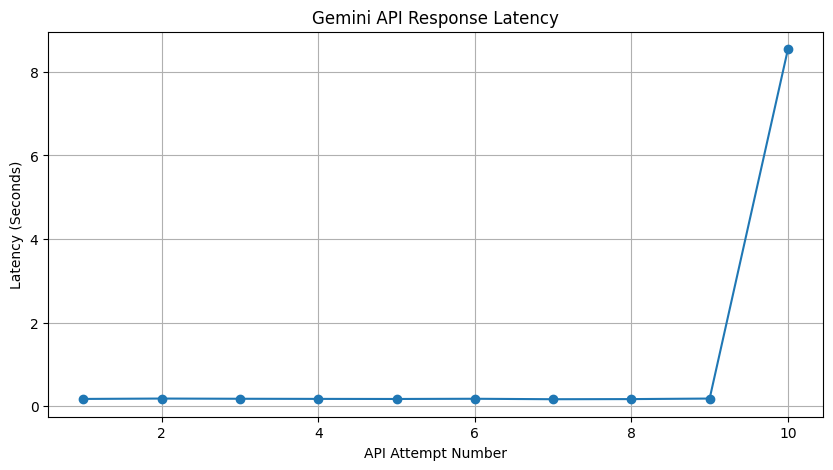

In [44]:
import matplotlib.pyplot as plt

if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(df) + 1),
        df["latency_seconds"],
        marker="o"
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Latency (Seconds)")

    plt.title("Gemini API Response Latency")

    plt.grid(True)

    plt.show()


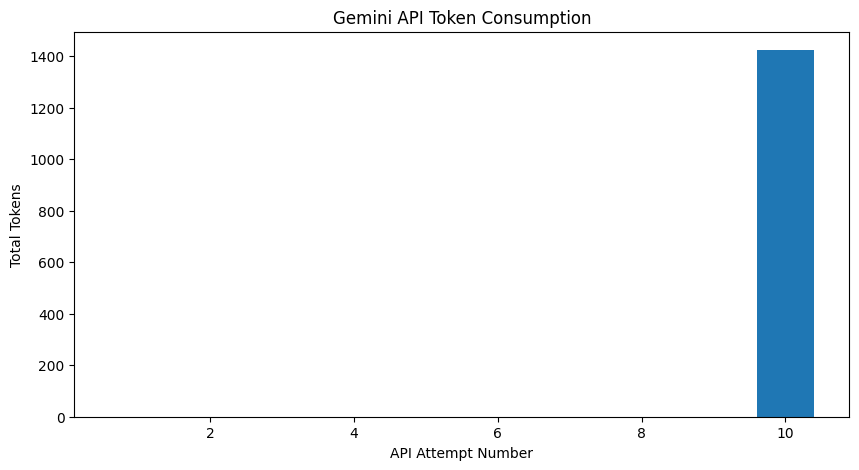

In [45]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["total_tokens"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Total Tokens")

    plt.title("Gemini API Token Consumption")

    plt.show()


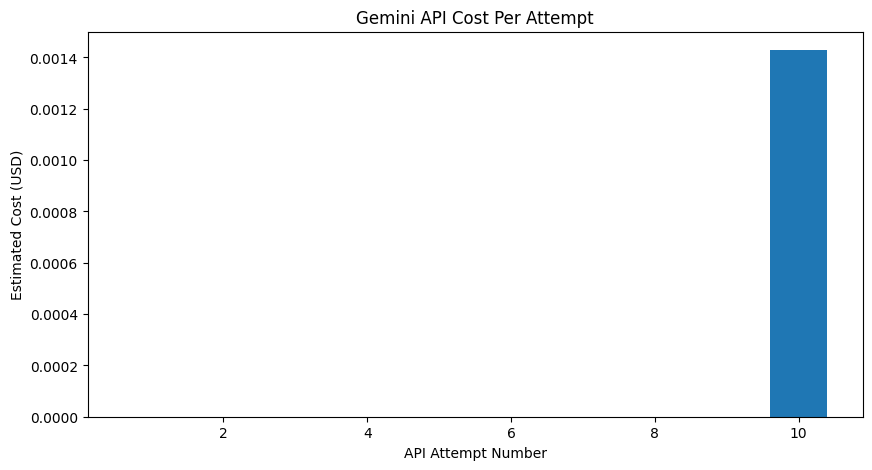

In [46]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["estimated_cost_usd"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Estimated Cost (USD)")

    plt.title("Gemini API Cost Per Attempt")

    plt.show()
